# v2.0b: Follow-Up Tests on the Walk-Forward Backtest

Where is Track B v2.0 weakest? Uses the backtest files already made (no new fits):
`trackbtv_w730_<season>_scored.csv` (v2.0), `trackbxg_w365_<season>_scored.csv` (v1.1) and
`baselines_<season>.csv` (rolling xG, home rate).

**Sections**
1. Setup
2. Results by subset: early season, rest / back-to-backs, unexpected starters, favorites
3. Cost of guessing the wrong starting goalie
4. Home-win share: predicted vs actual
5. Summary: what each finding points to in v2

Lower log loss is better. "bias" = mean predicted P(home win) minus actual home-win share (negative = home team
won more than predicted). Subsets are small, so every difference comes with a 90% bootstrap range.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config.settings import OUTPUT_DIR
from src.data.db import get_connection
from src.validation.scoring import log_loss, calibration_slope, paired_difference

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

BT = OUTPUT_DIR / "backtests"
SEASONS = ["20242025", "20252026"]
FILES = {"v2.0": "trackbtv_w730", "v1.1": "trackbxg_w365",     # labels of the backtests compared
         "v2.0d rest": "trackbtv_w730_r", "v2.0d rest+home": "trackbtv_w730_rh",  # used if present
         "v2.0e rest+finishing": "trackbtv_w730_rg", "v2.0f rest+travel": "trackbtv_w730_rt",
         "v2.0g rest+goalie rest": "trackbtv_w730_rk"}

COL = {"v1.1": "v11", "v2.0d rest": "v20d_r", "v2.0d rest+home": "v20d_rh", "v2.0e rest+finishing": "v20e_rg", "v2.0f rest+travel": "v20f_rt", "v2.0g rest+goalie rest": "v20g_rk"}
frames = []
for season in SEASONS:
    main = BT / f"{FILES['v2.0']}_{season}_scored.csv"
    if not main.exists():
        print(f"missing {main.name}"); continue
    d = pd.read_csv(main, parse_dates=["game_date"]).drop_duplicates("game_id", keep="last").rename(columns={"p_home": "p_v20"})
    for name, lab in FILES.items():
        if name == "v2.0":
            continue
        f = BT / f"{lab}_{season}_scored.csv"
        if f.exists():
            other = pd.read_csv(f, usecols=["game_id", "p_home"])
            if other["game_id"].duplicated().any():   # never let a duplicated file repeat games
                print(f"WARNING {f.name}: {other['game_id'].duplicated().sum()} duplicated games, kept the last of each")
                other = other.drop_duplicates("game_id", keep="last")
            d = d.merge(other.rename(columns={"p_home": "p_" + COL[name]}), on="game_id", how="left")
    b = BT / f"baselines_{season}.csv"
    if b.exists():
        d = d.merge(pd.read_csv(b, usecols=["game_id", "p_home_rate", "p_rolling_xg"]), on="game_id", how="left")
    frames.append(d)
df = pd.concat(frames, ignore_index=True).sort_values(["game_date", "game_id"]).reset_index(drop=True)
df["season"] = df["season"].astype(str)
MODELS = {"v2.0": "p_v20", "v2.0d rest": "p_v20d_r", "v2.0d rest+home": "p_v20d_rh",
          "v2.0e rest+finishing": "p_v20e_rg", "v2.0f rest+travel": "p_v20f_rt",
          "v2.0g rest+goalie rest": "p_v20g_rk", "v1.1": "p_v11",
          "rolling xG": "p_rolling_xg", "home rate": "p_home_rate"}
for k, v in MODELS.items():
    if v in df and df[v].isna().any():
        print(f"LEFT OUT {k}: predictions for {df[v].notna().sum():,} of {len(df):,} games (run unfinished or a season missing)")
MODELS = {k: v for k, v in MODELS.items() if v in df and df[v].notna().all()}
print(f"{len(df):,} games; models: {', '.join(MODELS)}")

2,624 games; models: v2.0, v2.0d rest, v2.0d rest+home, v2.0e rest+finishing, v2.0f rest+travel, v1.1, rolling xG, home rate


## 2. Results by subset

For each subset: games, log loss per model, v2.0 minus rolling xG (paired, 90% range), and v2.0's bias.

In [2]:
# Per-team context from the schedule of these games (each file holds the full regular season)
long = pd.concat([df[["game_id", "game_date", "season", "home"]].rename(columns={"home": "team"}).assign(side="home"),
                  df[["game_id", "game_date", "season", "away"]].rename(columns={"away": "team"}).assign(side="away")])
long = long.sort_values(["team", "game_date", "game_id"])
long["games_before"] = long.groupby(["season", "team"]).cumcount()
long["rest_days"] = long.groupby(["season", "team"])["game_date"].diff().dt.days
ctx = long.pivot_table(index="game_id", columns="side", values=["games_before", "rest_days"], aggfunc="first")
ctx.columns = [f"{a}_{b}" for a, b in ctx.columns]
df = df.drop(columns=[c for c in ctx.columns if c in df]).merge(ctx.reset_index(), on="game_id", how="left")

def subset_table(groups: dict) -> pd.DataFrame:
    rows = []
    for name, mask in groups.items():
        sub = df[mask]
        if len(sub) < 30:
            continue
        row = {"subset": name, "games": len(sub)}
        for m, col in MODELS.items():
            row[m] = log_loss(sub[col], sub["home_won"])
        if "rolling xG" in MODELS:
            r = paired_difference(sub, MODELS["v2.0"], MODELS["rolling xG"], n_boot=1000)
            row["v2.0 - rolling xG"] = f"{r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]"
        for m in [m for m in MODELS if m.startswith("v2.0")]:
            row[f"{m} bias"] = sub[MODELS[m]].mean() - sub["home_won"].mean()
        rows.append(row)
    return pd.DataFrame(rows).round(4)

everything = {"all games": df["game_id"].notna()}

### 2a. Early season

Ratings are carried over the summer (one off-season step, loosely identified). `games before` = the fewer of the
two teams' games already played this season.

In [3]:
gb = df[["games_before_home", "games_before_away"]].min(axis=1)
early = subset_table({**everything, "first 10 games": gb < 10, "games 10-29": (gb >= 10) & (gb < 30),
                      "game 30+": gb >= 30})
display(early)
first = df[gb < 10]
a, b = calibration_slope(first[MODELS["v2.0"]], first["home_won"])
print(f"v2.0 calibration slope in each team's first 10 games: {b:.2f} (1 = calibrated, >1 too cautious)")

,subset,games,v2.0,v2.0d rest,v2.0d rest+home,v2.0e rest+finishing,v2.0f rest+travel,v1.1,rolling xG,home rate,v2.0 - rolling xG,v2.0 bias,v2.0d rest bias,v2.0d rest+home bias,v2.0e rest+finishing bias,v2.0f rest+travel bias
0,all games,2624,0.6749,0.6732,0.6732,0.6728,0.6733,0.6773,0.6754,0.6899,"-0.0005 [-0.0038, +0.0028]",-0.0064,-0.0065,-0.0082,-0.0067,-0.0066
1,first 10 games,336,0.6740,0.6710,0.6705,0.6696,0.6714,0.6721,0.6781,0.6919,"-0.0041 [-0.0138, +0.0046]",0.0077,0.0077,0.0083,0.0069,0.0072
2,games 10-29,644,0.6797,0.6777,0.6775,0.6774,0.6781,0.6858,0.6774,0.6932,"+0.0023 [-0.0031, +0.0078]",0.0164,0.0160,0.0138,0.0153,0.0158
3,game 30+,1644,0.6732,0.6720,0.6721,0.6717,0.6718,0.6751,0.6740,0.6883,"-0.0009 [-0.0053, +0.0033]",-0.0182,-0.0182,-0.0202,-0.0182,-0.0182


v2.0 calibration slope in each team's first 10 games: 0.98 (1 = calibrated, >1 too cautious)


### 2b. Rest and back-to-backs

The model has no fatigue term. If tired teams lose more than predicted, the bias shows it: an away team on the
second night of a back-to-back should make the home team win *more* than predicted (negative bias).

In [4]:
h1 = df["rest_days_home"] == 1
a1 = df["rest_days_away"] == 1
rest = subset_table({**everything,
                     "home on back-to-back only": h1 & ~a1,
                     "away on back-to-back only": a1 & ~h1,
                     "both on back-to-back": h1 & a1,
                     "neither": ~h1 & ~a1,
                     "home 3+ days rest, away back-to-back": (df["rest_days_home"] >= 3) & a1})
display(rest)
for name, mask in [("home on back-to-back only", h1 & ~a1), ("away on back-to-back only", a1 & ~h1)]:
    s = df[mask]
    if len(s) >= 30:
        se = np.sqrt(s["home_won"].var() / len(s))
        preds = ", ".join(f"{m} {s[MODELS[m]].mean():.1%}" for m in MODELS if m.startswith("v2.0"))
        print(f"{name}: actual home win {s['home_won'].mean():.1%} (± {1.645 * se:.1%} at 90%); predicted: {preds}")

,subset,games,v2.0,v2.0d rest,v2.0d rest+home,v2.0e rest+finishing,v2.0f rest+travel,v1.1,rolling xG,home rate,v2.0 - rolling xG,v2.0 bias,v2.0d rest bias,v2.0d rest+home bias,v2.0e rest+finishing bias,v2.0f rest+travel bias
0,all games,2624,0.6749,0.6732,0.6732,0.6728,0.6733,0.6773,0.6754,0.6899,"-0.0005 [-0.0038, +0.0028]",-0.0064,-0.0065,-0.0082,-0.0067,-0.0066
1,home on back-to-back only,152,0.6916,0.6871,0.6860,0.6864,0.6885,0.6976,0.6832,0.6972,"+0.0084 [-0.0044, +0.0213]",0.0533,0.0181,0.0165,-0.0011,0.0177
2,away on back-to-back only,416,0.6549,0.6458,0.6460,0.6429,0.6449,0.6532,0.6552,0.6782,"-0.0004 [-0.0085, +0.0078]",-0.0863,-0.0563,-0.0579,-0.0422,-0.0560
3,both on back-to-back,130,0.6836,0.6841,0.6854,0.6857,0.6852,0.6809,0.6961,0.6801,"-0.0125 [-0.0282, +0.0028]",-0.0661,-0.0667,-0.0685,-0.0720,-0.0663
4,neither,1926,0.6773,0.6773,0.6773,0.6773,0.6774,0.6807,0.6777,0.6926,"-0.0004 [-0.0040, +0.0035]",0.0102,0.0064,0.0046,0.0049,0.0062
5,"home 3+ days rest, away back-to-back",142,0.6396,0.6332,0.6337,0.6312,0.6328,0.6400,0.6359,0.6820,"+0.0037 [-0.0103, +0.0183]",-0.0611,-0.0313,-0.0331,-0.0167,-0.0303


home on back-to-back only: actual home win 48.7% (± 6.7% at 90%); predicted: v2.0 54.0%, v2.0d rest 50.5%, v2.0d rest+home 50.3%, v2.0e rest+finishing 48.6%, v2.0f rest+travel 50.5%
away on back-to-back only: actual home win 62.0% (± 3.9% at 90%); predicted: v2.0 53.4%, v2.0d rest 56.4%, v2.0d rest+home 56.2%, v2.0e rest+finishing 57.8%, v2.0f rest+travel 56.4%


### Travel and crowded stretches (v2.0f)

Schedule context from `src/processing/schedule_context.py` (same numbers the model uses): km flown since the last game,
time zones crossed, 3rd game in 4 nights. The question: is the away back-to-back gap bigger after long overnight trips?


In [5]:
from src.processing.schedule_context import schedule_context
c_local = get_connection()
sc = schedule_context(c_local)
c_local.close()
df = df.drop(columns=[c for c in sc.columns if c in df and c != "game_id"]).merge(sc, on="game_id", how="left")
a1, h1 = df["b2b_away"] == 1, df["b2b_home"] == 1
travel = subset_table({
    "away b2b, under 500 km": a1 & ~h1 & (df["km_away"] < 500),
    "away b2b, 500-1,200 km": a1 & ~h1 & df["km_away"].between(500, 1200),
    "away b2b, over 1,200 km": a1 & ~h1 & (df["km_away"] > 1200),
    "away crossed 2+ time zones (rest <= 2)": df["tz_away"] >= 2,
    "away 3rd game in 4 nights": df["dense_away"] == 1,
    "home 3rd game in 4 nights": df["dense_home"] == 1,
})
display(travel)
print("bias = mean predicted - actual home win; negative = home won more than predicted. "
      "90% noise band on a subset's actual rate is about +-1.645*sqrt(p(1-p)/games), e.g. +-0.04 for 400 games.")


,subset,games,v2.0,v2.0d rest,v2.0d rest+home,v2.0e rest+finishing,v2.0f rest+travel,v1.1,rolling xG,home rate,v2.0 - rolling xG,v2.0 bias,v2.0d rest bias,v2.0d rest+home bias,v2.0e rest+finishing bias,v2.0f rest+travel bias
0,"away b2b, under 500 km",174,0.6674,0.6581,0.6589,0.6555,0.6585,0.6675,0.6640,0.6798,"+0.0035 [-0.0103, +0.0162]",-0.0777,-0.0474,-0.0487,-0.0335,-0.0483
1,"away b2b, 500-1,200 km",213,0.6437,0.6352,0.6350,0.6324,0.6341,0.6427,0.6487,0.6776,"-0.0051 [-0.0157, +0.0041]",-0.0901,-0.0603,-0.0621,-0.0459,-0.0595
2,away crossed 2+ time zones (rest <= 2),137,0.6934,0.6939,0.6942,0.6940,0.6943,0.6975,0.6844,0.6891,"+0.0090 [-0.0067, +0.0238]",-0.0174,-0.0225,-0.0244,-0.0254,-0.0269
3,away 3rd game in 4 nights,576,0.6641,0.6595,0.6600,0.6584,0.6596,0.6655,0.6673,0.6846,"-0.0033 [-0.0098, +0.0037]",-0.0397,-0.0293,-0.0310,-0.0258,-0.0251
4,home 3rd game in 4 nights,446,0.6845,0.6844,0.6843,0.6853,0.6839,0.6891,0.6819,0.6930,"+0.0026 [-0.0057, +0.0103]",0.0202,0.0148,0.0132,0.0106,0.0103


bias = mean predicted - actual home win; negative = home won more than predicted. 90% noise band on a subset's actual rate is about +-1.645*sqrt(p(1-p)/games), e.g. +-0.04 for 400 games.


### 2c. Unexpected starting goalies

The backtest used the actual starters. "Unexpected" = the starter was not the team's most frequent starter in its
last 10 games (what `predict_day` would have guessed). These are mostly backup starts.

In [6]:
from src.models.game_model import default_starter
conn = get_connection()
guess = {}
for r in df[["game_id", "game_date", "home", "away"]].itertuples():
    day = str(r.game_date.date())
    guess[(r.game_id, "home")] = default_starter(conn, r.home, day)
    guess[(r.game_id, "away")] = default_starter(conn, r.away, day)
df["guess_home"] = [guess[(g, "home")] for g in df["game_id"]]
df["guess_away"] = [guess[(g, "away")] for g in df["game_id"]]
df["surprise_home"] = df["guess_home"].notna() & (df["guess_home"] != df["home_goalie"])
df["surprise_away"] = df["guess_away"].notna() & (df["guess_away"] != df["away_goalie"])
print(f"Default guess wrong: home {df.surprise_home.mean():.1%}, away {df.surprise_away.mean():.1%} of team-games")
goalies = subset_table({**everything,
                        "no surprise starter": ~df.surprise_home & ~df.surprise_away,
                        "home surprise starter": df.surprise_home & ~df.surprise_away,
                        "away surprise starter": df.surprise_away & ~df.surprise_home,
                        "both surprise": df.surprise_home & df.surprise_away})
display(goalies)

Default guess wrong: home 38.0%, away 45.4% of team-games


,subset,games,v2.0,v2.0d rest,v2.0d rest+home,v2.0e rest+finishing,v2.0f rest+travel,v1.1,rolling xG,home rate,v2.0 - rolling xG,v2.0 bias,v2.0d rest bias,v2.0d rest+home bias,v2.0e rest+finishing bias,v2.0f rest+travel bias
0,all games,2624,0.6749,0.6732,0.6732,0.6728,0.6733,0.6773,0.6754,0.6899,"-0.0005 [-0.0038, +0.0028]",-0.0064,-0.0065,-0.0082,-0.0067,-0.0066
1,no surprise starter,896,0.6632,0.6619,0.6620,0.6616,0.6620,0.6648,0.6652,0.6898,"-0.0020 [-0.0082, +0.0035]",-0.0099,-0.0116,-0.0133,-0.0124,-0.0115
2,home surprise starter,538,0.6882,0.6871,0.6866,0.6862,0.6873,0.6882,0.6904,0.6906,"-0.0021 [-0.0093, +0.0053]",-0.0037,-0.0068,-0.0087,-0.0090,-0.0067
3,away surprise starter,732,0.6794,0.6778,0.6781,0.6776,0.6777,0.6847,0.6798,0.6914,"-0.0004 [-0.0067, +0.0054]",0.0068,0.0105,0.0090,0.0124,0.0102
4,both surprise,458,0.6748,0.6718,0.6718,0.6715,0.6717,0.6775,0.6706,0.6871,"+0.0042 [-0.0031, +0.0119]",-0.0237,-0.0234,-0.0253,-0.0236,-0.0235


### Back-to-backs × backup goalies (is the away back-to-back gap really a goalie gap?)

"Backup" = the actual starter is not the team's usual starter (most starts in its last 10 games, the default guess).
The backtest already uses the actual starter's rating, so if the gap sits in **back-to-back + backup** games, the
goalie ratings are too close together (strong shrinkage) and the fix is the v2.1 goalie layer, not more rest terms.


In [7]:
a1, h1 = df["rest_days_away"] == 1, df["rest_days_home"] == 1
bu_a, bu_h = df["surprise_away"], df["surprise_home"]
goalie_b2b = subset_table({
    "away b2b, usual starter": a1 & ~h1 & ~bu_a,
    "away b2b, backup started": a1 & ~h1 & bu_a,
    "away backup, rested (no b2b)": ~a1 & bu_a & ~bu_h,
    "away usual starter, rested": ~a1 & ~bu_a & ~bu_h,
    "home b2b, usual starter": h1 & ~a1 & ~bu_h,
    "home b2b, backup started": h1 & ~a1 & bu_h,
    "home backup, rested (no b2b)": ~h1 & bu_h & ~bu_a,
})
display(goalie_b2b)
print(f"Away teams start the backup in {bu_a[a1 & ~h1].mean():.0%} of their back-to-backs vs {bu_a[~a1].mean():.0%} otherwise")
print("Read: if 'backup started' rows carry most of the negative bias (and 'backup, rested' is negative too), "
      "backups are under-penalized everywhere -> v2.1 goalie layer. If 'usual starter' rows are as biased, it is fatigue.")


,subset,games,v2.0,v2.0d rest,v2.0d rest+home,v2.0e rest+finishing,v2.0f rest+travel,v1.1,rolling xG,home rate,v2.0 - rolling xG,v2.0 bias,v2.0d rest bias,v2.0d rest+home bias,v2.0e rest+finishing bias,v2.0f rest+travel bias
0,"away b2b, usual starter",140,0.6425,0.6258,0.6259,0.6193,0.6243,0.6387,0.6433,0.6679,"-0.0008 [-0.0152, +0.0131]",-0.1507,-0.1210,-0.1227,-0.1074,-0.1198
1,"away b2b, backup started",276,0.6612,0.6559,0.6562,0.6549,0.6554,0.6605,0.6613,0.6834,"-0.0001 [-0.0101, +0.0088]",-0.0537,-0.0235,-0.0251,-0.0091,-0.0237
2,"away backup, rested (no b2b)",519,0.6863,0.6861,0.6863,0.6862,0.6862,0.6929,0.6858,0.6953,"+0.0005 [-0.0068, +0.0086]",0.0325,0.0274,0.0259,0.0254,0.0269
3,"away usual starter, rested",792,0.6668,0.6667,0.6667,0.6668,0.6672,0.6688,0.6679,0.6916,"-0.0011 [-0.0070, +0.0048]",0.0024,-0.0026,-0.0043,-0.0048,-0.0027
4,"home b2b, usual starter",48,0.6844,0.6790,0.6784,0.6802,0.6827,0.6934,0.6644,0.6961,"+0.0200 [-0.0021, +0.0416]",0.0455,0.0105,0.0087,-0.0084,0.0091
5,"home b2b, backup started",104,0.6949,0.6909,0.6895,0.6893,0.6911,0.6996,0.6918,0.6977,"+0.0031 [-0.0133, +0.0193]",0.0569,0.0216,0.0201,0.0023,0.0216
6,"home backup, rested (no b2b)",455,0.6917,0.6888,0.6883,0.6874,0.6889,0.6912,0.6935,0.6901,"-0.0018 [-0.0093, +0.0060]",-0.0064,-0.0060,-0.0079,-0.0057,-0.0060


Away teams start the backup in 66% of their back-to-backs vs 40% otherwise
Read: if 'backup started' rows carry most of the negative bias (and 'backup, rested' is negative too), backups are under-penalized everywhere -> v2.1 goalie layer. If 'usual starter' rows are as biased, it is fatigue.


In [8]:
# The exact v2.0g feature: did this game's starter also start yesterday (zero rest)?
from src.processing.game_table import goalie_rest
c_local = get_connection()
gr = goalie_rest(c_local)
c_local.close()
for side in ("home", "away"):
    df = df.drop(columns=[c for c in (f"grest_{side}", f"g2b_{side}") if c in df]).merge(
        gr.rename(columns={"goalie_id": f"{side}_goalie", "grest": f"grest_{side}", "g2b": f"g2b_{side}"}),
        on=["game_id", f"{side}_goalie"], how="left")
    df[f"g2b_{side}"] = df[f"g2b_{side}"].fillna(0).astype(int)
a1, h1 = df["rest_days_away"] == 1, df["rest_days_home"] == 1
ga, gh = df["g2b_away"] == 1, df["g2b_home"] == 1
goalie_zero = subset_table({
    "away goalie on zero rest": ga & ~gh,
    "away b2b, goalie fresh": a1 & ~ga & ~gh,
    "home goalie on zero rest": gh & ~ga,
    "home b2b, goalie fresh": h1 & ~gh & ~ga,
})
display(goalie_zero)
print(f"Same goalie both nights: away {ga[a1].mean():.0%} of away back-to-backs, home {gh[h1].mean():.0%} of home back-to-backs")


,subset,games,v2.0,v2.0d rest,v2.0d rest+home,v2.0e rest+finishing,v2.0f rest+travel,v1.1,rolling xG,home rate,v2.0 - rolling xG,v2.0 bias,v2.0d rest bias,v2.0d rest+home bias,v2.0e rest+finishing bias,v2.0f rest+travel bias
0,away goalie on zero rest,40,0.6701,0.6719,0.6707,0.6702,0.6708,0.6722,0.6778,0.6960,"-0.0077 [-0.0310, +0.0172]",0.0411,0.0653,0.0640,0.0739,0.0663
1,"away b2b, goalie fresh",491,0.6598,0.6521,0.6526,0.6505,0.6518,0.6573,0.6622,0.6768,"-0.0025 [-0.0097, +0.0049]",-0.0930,-0.0696,-0.0713,-0.0596,-0.0694
2,"home b2b, goalie fresh",249,0.6812,0.6785,0.6783,0.6796,0.6797,0.6837,0.6795,0.6874,"+0.0017 [-0.0099, +0.0128]",-0.0108,-0.0315,-0.0332,-0.0448,-0.0316


Same goalie both nights: away 7% of away back-to-backs, home 8% of home back-to-backs


### 2d. Favorites vs coin flips

Grouped by how strongly v2.0 favored one side. Bias here is for the favorite: predicted minus actual share of
favorite wins (negative = favorites won more than predicted, i.e. the model was too cautious).

In [9]:
p = df[MODELS["v2.0"]]
fav = np.maximum(p, 1 - p)
fav_won = np.where(p >= 0.5, df["home_won"], 1 - df["home_won"])
bins = pd.cut(fav, [0.5, 0.55, 0.6, 0.65, 1.0], labels=["50-55%", "55-60%", "60-65%", "65%+"], include_lowest=True)
t = pd.DataFrame({"bin": bins, "fav": fav, "won": fav_won}).groupby("bin", observed=True).agg(
    games=("won", "size"), predicted=("fav", "mean"), actual=("won", "mean"))
t["band_90"] = 1.645 * np.sqrt(t.predicted * (1 - t.predicted) / t.games)
t["favorite bias"] = t.predicted - t.actual
t["inside"] = t["favorite bias"].abs() <= t.band_90
display(t.round(3))
check("favorites win about as often as predicted in every group", t["inside"].all())

,games,predicted,actual,band_90,favorite bias,inside
bin,,,,,,
50-55%,1011,0.524,0.517,0.026,0.007,True
55-60%,861,0.573,0.553,0.028,0.020,True
60-65%,458,0.622,0.642,0.037,-0.020,True
65%+,294,0.687,0.701,0.044,-0.014,True


PASS   favorites win about as often as predicted in every group


## 3. Cost of guessing the wrong starting goalie

Live predictions guess the starter; the backtest used the real one. Each game is recomputed with the guessed
starters by swapping goalie offsets in the saved scoring rates (no refit):
lam_home' = lam_home * exp(gamma_away_actual - gamma_away_guess), and the same for the away side.
The change in P(home win) from the exact game model (plug-in, posterior-mean rates) is added to the logged prediction.

In [10]:
from src.processing.goalie import goalie_game_xg
from src.processing.game_table import goalie_gamma
from src.processing.late_game import load_params
from src.models.game_model import outcome_probs

gg = goalie_game_xg(conn)
gam = goalie_gamma(gg, sorted(df["game_date"].dt.normalize().unique()))
gam["game_date"] = pd.to_datetime(gam["game_date"])
look = gam.set_index(["game_date", "goalie_id"])["gamma"]
def offset(day, gid):
    if pd.isna(gid):
        return 0.0
    return float(look.get((day, int(gid)), 0.0))
day = df["game_date"].dt.normalize()
df["gamma_home_guess"] = [offset(d, g) for d, g in zip(day, df["guess_home"])]
df["gamma_away_guess"] = [offset(d, g) for d, g in zip(day, df["guess_away"])]

late = load_params(OUTPUT_DIR / "models" / "late_game.json")
RHO = 0.52                                       # tie inflation (v1.1 and v2.0 both estimate about 0.52)
lh, la = df["lam_home"].to_numpy(), df["lam_away"].to_numpy()
lh_g = lh * np.exp(df["gamma_away"] - df["gamma_away_guess"]).to_numpy()
la_g = la * np.exp(df["gamma_home"] - df["gamma_home_guess"]).to_numpy()
p_act = outcome_probs(lh, la, np.full(len(df), RHO), late)["home_win"]
p_gss = outcome_probs(lh_g, la_g, np.full(len(df), RHO), late)["home_win"]
df["p_v20_guess"] = np.clip(df[MODELS["v2.0"]] + (p_gss - p_act), 0.01, 0.99)

wrong = df.surprise_home | df.surprise_away
r = paired_difference(df, "p_v20_guess", MODELS["v2.0"])
print(f"Games with at least one wrong guess: {wrong.mean():.1%} ({wrong.sum():,} of {len(df):,})")
print(f"Mean change in P(home win) when the guess is wrong: {np.abs(df.p_v20_guess - df[MODELS['v2.0']])[wrong].mean() * 100:.1f} pts")
print(f"Log loss, actual starters {log_loss(df[MODELS['v2.0']], df.home_won):.4f} vs guessed {log_loss(df.p_v20_guess, df.home_won):.4f}")
print(f"Guessed minus actual, all games: {r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")
w = df[wrong]
r2 = paired_difference(w, "p_v20_guess", MODELS["v2.0"])
print(f"Guessed minus actual, games with a wrong guess: {r2['difference']:+.4f} [{r2['lo']:+.4f}, {r2['hi']:+.4f}]")
print("\nRead: the all-games number is what live predictions lose to starter guessing; compare it with the "
      "v2.0 vs v1.1 gain (0.0025) to see whether waiting for confirmed starters matters.")

Games with at least one wrong guess: 65.9% (1,728 of 2,624)
Mean change in P(home win) when the guess is wrong: 0.8 pts
Log loss, actual starters 0.6749 vs guessed 0.6750
Guessed minus actual, all games: +0.0001 [-0.0004, +0.0007]
Guessed minus actual, games with a wrong guess: +0.0002 [-0.0008, +0.0010]

Read: the all-games number is what live predictions lose to starter guessing; compare it with the v2.0 vs v1.1 gain (0.0025) to see whether waiting for confirmed starters matters.


## 4. Home-win share: predicted vs actual

In-sample (Phase 6) the model was about 1 point low (53.4% vs 54.2%). If it is low out of sample too, home ice
(one league-wide value) may need to vary by season.

,games,actual,v2.0,v2.0d rest,v2.0d rest+home,v2.0e rest+finishing,v2.0f rest+travel,v1.1,rolling xG,home rate,v2.0 - actual,90% band
season,,,,,,,,,,,,
20242025,1312.0,0.5625,0.5335,0.5341,0.5319,0.5343,0.5342,0.5363,0.5339,0.5338,-0.0290,0.0225
20252026,1312.0,0.5221,0.5384,0.5375,0.5363,0.5369,0.5373,0.5393,0.5424,0.5410,0.0163,0.0227
both,2624.0,0.5423,0.5359,0.5358,0.5341,0.5356,0.5357,0.5378,0.5382,0.5374,-0.0064,0.0160


CHECK  20242025: predicted home-win share within the 90% band   (53.3% vs 56.2%)
PASS   20252026: predicted home-win share within the 90% band   (53.8% vs 52.2%)
PASS   both: predicted home-win share within the 90% band   (53.6% vs 54.2%)


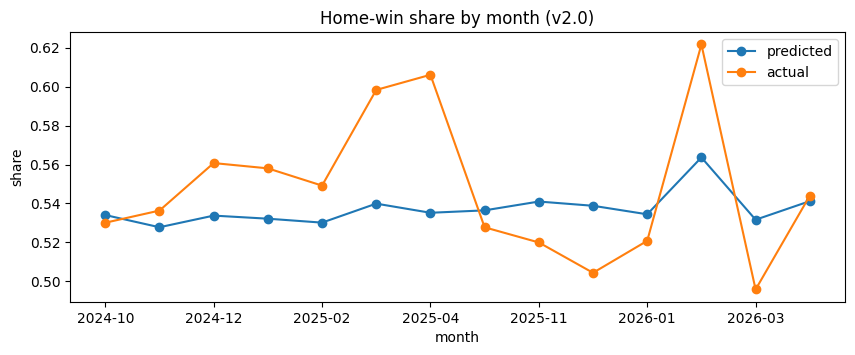

In [11]:
hs = df.groupby("season").agg(games=("home_won", "size"), actual=("home_won", "mean"),
                              **{m: (c, "mean") for m, c in MODELS.items()})
hs.loc["both"] = [len(df), df.home_won.mean()] + [df[c].mean() for c in MODELS.values()]
hs["v2.0 - actual"] = hs["v2.0"] - hs["actual"]
hs["90% band"] = 1.645 * np.sqrt(hs["actual"] * (1 - hs["actual"]) / hs["games"])
display(hs.round(4))
for s, row in hs.iterrows():
    check(f"{s}: predicted home-win share within the 90% band", abs(row["v2.0 - actual"]) <= row["90% band"],
          f"{row['v2.0']:.1%} vs {row['actual']:.1%}")
by_m = df.assign(month=df.game_date.dt.to_period("M").astype(str)).groupby("month").agg(
    predicted=(MODELS["v2.0"], "mean"), actual=("home_won", "mean"), games=("home_won", "size"))
ax = by_m[["predicted", "actual"]].plot(marker="o", figsize=(10, 3.5), title="Home-win share by month (v2.0)")
ax.set_ylabel("share"); plt.show()

## 5. Summary

In [12]:
lines = []
e = early.set_index("subset")
if "first 10 games" in e.index and "rolling xG" in MODELS:
    lines.append(f"Early season (first 10 games): v2.0 {e.loc['first 10 games', 'v2.0']:.4f} vs rolling xG "
                 f"{e.loc['first 10 games', 'rolling xG']:.4f}; v2.0 - rolling xG {e.loc['first 10 games', 'v2.0 - rolling xG']}")
rr = rest.set_index("subset")
for k in ["home on back-to-back only", "away on back-to-back only"]:
    if k in rr.index:
        lines.append(f"{k}: " + ", ".join(f"{m} bias {rr.loc[k, f'{m} bias']:+.3f}" for m in MODELS
                                          if m.startswith("v2.0") and f"{m} bias" in rr.columns)
                     + " (negative = home won more than predicted)")
if "travel" in globals() and len(travel):
    tt = travel.set_index("subset")
    for k in tt.index:
        lines.append(f"{k} ({int(tt.loc[k, 'games'])} games): " + ", ".join(
            f"{m} bias {tt.loc[k, f'{m} bias']:+.3f}" for m in MODELS if m.startswith("v2.0") and f"{m} bias" in tt.columns))
if "goalie_b2b" in globals() and len(goalie_b2b):
    gb = goalie_b2b.set_index("subset")
    for k in gb.index:
        lines.append(f"{k} ({int(gb.loc[k, 'games'])} games): " + ", ".join(
            f"{m} bias {gb.loc[k, f'{m} bias']:+.3f}" for m in MODELS if m.startswith("v2.0") and f"{m} bias" in gb.columns))
if "goalie_zero" in globals() and len(goalie_zero):
    gz = goalie_zero.set_index("subset")
    for k in gz.index:
        lines.append(f"{k} ({int(gz.loc[k, 'games'])} games): " + ", ".join(
            f"{m} bias {gz.loc[k, f'{m} bias']:+.3f}" for m in MODELS if m.startswith("v2.0") and f"{m} bias" in gz.columns))
lines.append(f"Wrong starter guess in {wrong.mean():.1%} of games; costs {r['difference']:+.4f} log loss overall")
lines.append(f"Home-win share: predicted {df[MODELS['v2.0']].mean():.1%} vs actual {df.home_won.mean():.1%}")
print("\n".join(lines))

Early season (first 10 games): v2.0 0.6740 vs rolling xG 0.6781; v2.0 - rolling xG -0.0041 [-0.0138, +0.0046]
home on back-to-back only: v2.0 bias +0.053, v2.0d rest bias +0.018, v2.0d rest+home bias +0.017, v2.0e rest+finishing bias -0.001, v2.0f rest+travel bias +0.018 (negative = home won more than predicted)
away on back-to-back only: v2.0 bias -0.086, v2.0d rest bias -0.056, v2.0d rest+home bias -0.058, v2.0e rest+finishing bias -0.042, v2.0f rest+travel bias -0.056 (negative = home won more than predicted)
away b2b, under 500 km (174 games): v2.0 bias -0.078, v2.0d rest bias -0.047, v2.0d rest+home bias -0.049, v2.0e rest+finishing bias -0.034, v2.0f rest+travel bias -0.048
away b2b, 500-1,200 km (213 games): v2.0 bias -0.090, v2.0d rest bias -0.060, v2.0d rest+home bias -0.062, v2.0e rest+finishing bias -0.046, v2.0f rest+travel bias -0.059
away crossed 2+ time zones (rest <= 2) (137 games): v2.0 bias -0.017, v2.0d rest bias -0.022, v2.0d rest+home bias -0.024, v2.0e rest+finish